# Ngày 1 — EDA phát triển Xoaif Garden

Notebook này chỉ đọc kho restricted đã dựng từ các đơn có ngày địa phương **trước `test_start`**. Chỉ số tiền, văn bản, lịch sử trạng thái, nhãn mua lại và mọi bản ghi trong giai đoạn test không được nạp. Khóa split và manifest được kiểm tra trước khi truy vấn.

In [1]:
from datetime import date
import hashlib
import json
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import yaml

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / 'config' / 'split.yaml').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'config' / 'split.yaml').is_file():
    raise RuntimeError('Run notebook from the project folder.')
config_path = ROOT / 'config' / 'split.yaml'
lock_path = ROOT / 'config' / 'split.lock.json'
config_bytes = config_path.read_bytes()
config = yaml.safe_load(config_bytes)
lock = json.loads(lock_path.read_text(encoding='utf-8'))
config_hash = hashlib.sha256(config_bytes).hexdigest()
assert config.get('status') == 'locked' and config_hash == lock['config_sha256']
assert config['snapshot_id'] == lock['snapshot_id']
snapshot_manifest = ROOT / 'data' / 'raw' / 'pancake_orders' / config['snapshot_id'] / 'manifest.json'
manifest_hash = hashlib.sha256(snapshot_manifest.read_bytes()).hexdigest()
assert manifest_hash == lock['snapshot_manifest_sha256'] == config['snapshot_manifest_sha256']
TEST_START = date.fromisoformat(str(config['test_start']))
db_path = ROOT / 'data' / 'restricted' / 'xoaif_dev.duckdb'
connection = duckdb.connect(str(db_path), read_only=True)
max_dev_date = connection.execute('SELECT MAX(local_date) FROM fact_orders').fetchone()[0]
assert max_dev_date is None or max_dev_date < TEST_START, 'Development warehouse crossed test_start.'
out_tables = ROOT / 'outputs' / 'tables'
out_figures = ROOT / 'outputs' / 'figures'
out_tables.mkdir(parents=True, exist_ok=True)
out_figures.mkdir(parents=True, exist_ok=True)
print(f'Snapshot: {config["snapshot_id"]}; development dates strictly before {TEST_START}.')
print(f'Latest warehouse date: {max_dev_date}; test labels loaded: no.')

Snapshot: 20261024T052943Z; development dates strictly before 2025-10-22.
Latest warehouse date: 2025-10-21; test labels loaded: no.


In [2]:
monthly = connection.execute(
    """SELECT date_trunc('month', local_date)::DATE AS month_start,
              COUNT(*) AS valid_orders
       FROM fact_orders
       WHERE status_code = 3 AND local_date < ?
       GROUP BY 1 ORDER BY 1""",
    [TEST_START],
).df()
observed_month_buckets = int(len(monthly))
if not monthly.empty:
    full_months = pd.date_range(monthly['month_start'].min(), monthly['month_start'].max(), freq='MS')
    monthly = (monthly.set_index('month_start').reindex(full_months, fill_value=0)
               .rename_axis('month_start').reset_index())
monthly.to_csv(out_tables / 'day1_monthly_valid_orders.csv', index=False, encoding='utf-8-sig')

freq = connection.execute(
    """SELECT customer_key, COUNT(*) AS purchase_frequency
       FROM fact_orders
       WHERE status_code = 3 AND customer_key IS NOT NULL AND local_date < ?
       GROUP BY customer_key""",
    [TEST_START],
).df()
bands = pd.cut(freq['purchase_frequency'], bins=[0, 1, 3, 7, float('inf')],
                labels=['1', '2-3', '4-7', '8+'], include_lowest=True)
frequency_bands = bands.value_counts(sort=False).rename_axis('orders_per_customer').reset_index(name='customer_count')
frequency_bands.to_csv(out_tables / 'day1_customer_frequency_bands.csv', index=False, encoding='utf-8-sig')

basket = connection.execute(
    """SELECT distinct_product_count
       FROM fact_orders
       WHERE status_code = 3 AND local_date < ?""",
    [TEST_START],
).df()
basket['basket_size_band'] = pd.cut(basket['distinct_product_count'],
    bins=[-1, 0, 1, 3, 7, float('inf')], labels=['0', '1', '2-3', '4-7', '8+'])
basket_bands = basket['basket_size_band'].value_counts(sort=False).rename_axis('distinct_products_per_order').reset_index(name='order_count')
basket_bands.to_csv(out_tables / 'day1_basket_size_bands.csv', index=False, encoding='utf-8-sig')

status_counts = connection.execute(
    'SELECT status_code, COUNT(*) AS order_count FROM fact_orders WHERE local_date < ? GROUP BY 1 ORDER BY 1',
    [TEST_START],
).df()
valid_orders = int(status_counts.loc[status_counts['status_code'] == 3, 'order_count'].sum())
unique_customers = int(freq['customer_key'].nunique())
summary = {
    'snapshot_id': config['snapshot_id'],
    'development_exclusive_end': TEST_START.isoformat(),
    'development_order_count': int(status_counts['order_count'].sum()),
    'valid_status_3_order_count': valid_orders,
    'eligible_customer_count_in_development': unique_customers,
    'observed_month_buckets': observed_month_buckets,
    'calendar_month_buckets_in_range': int(len(monthly)),
    'median_orders_per_customer': float(freq['purchase_frequency'].median()) if len(freq) else None,
    'median_distinct_products_per_valid_order': float(basket['distinct_product_count'].median()) if len(basket) else None,
    'money_fields_used': False,
    'labels_loaded': False,
}
(out_tables / 'day1_eda_summary.json').write_text(json.dumps(summary, indent=2) + '\n', encoding='utf-8')
print(status_counts.to_string(index=False))
print(f'Valid status-3 orders: {valid_orders}; distinct development customers: {unique_customers}.')
print(f'Month buckets: {len(monthly)}; median valid orders/customer: {summary["median_orders_per_customer"]}.')
print(f'Median distinct products/valid order: {summary["median_distinct_products_per_valid_order"]}.')

 status_code  order_count
           3         6400
           5           13
           6          104
Valid status-3 orders: 6400; distinct development customers: 5174.
Month buckets: 19; median valid orders/customer: 1.0.
Median distinct products/valid order: 4.0.


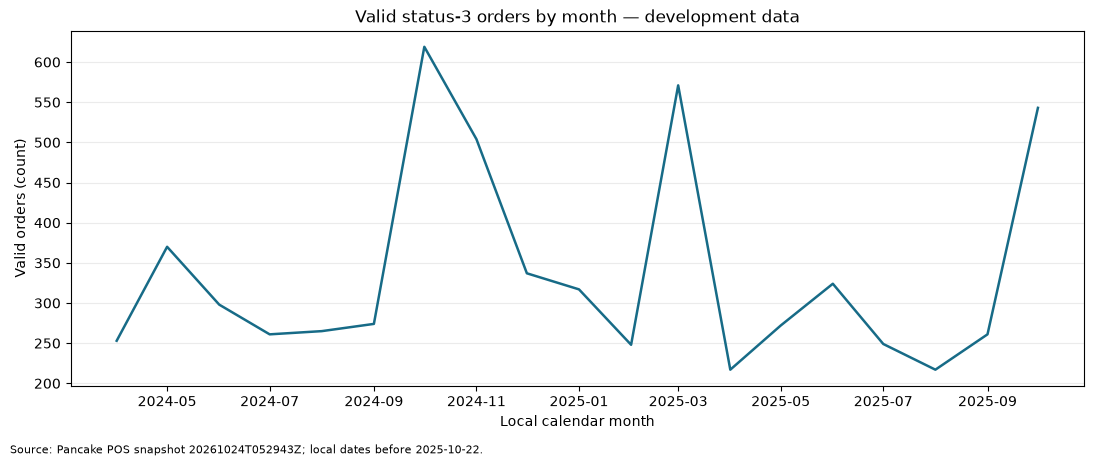

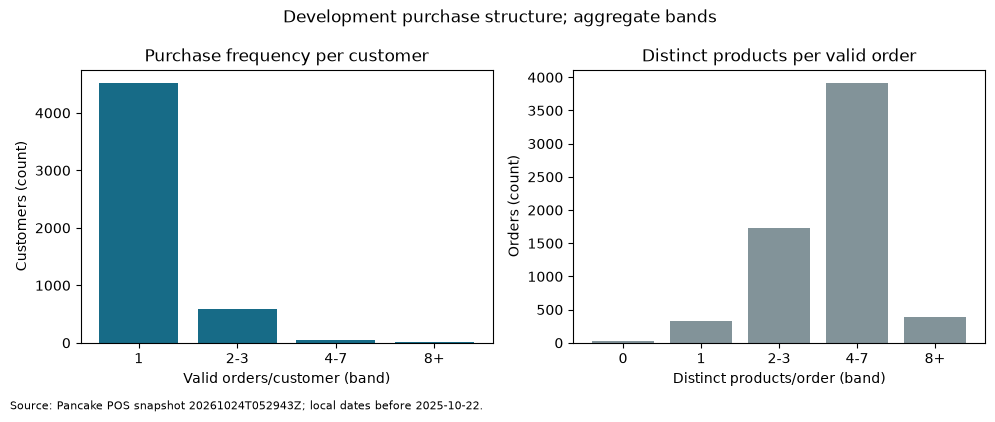

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly['month_start'], monthly['valid_orders'], color='#176B87', linewidth=1.8)
ax.set_title('Valid status-3 orders by month — development data')
ax.set_xlabel('Local calendar month')
ax.set_ylabel('Valid orders (count)')
ax.grid(axis='y', alpha=0.25)
fig.text(0.01, -0.02, f'Source: Pancake POS snapshot {config["snapshot_id"]}; local dates before {TEST_START}.', fontsize=8)
fig.tight_layout()
fig.savefig(out_figures / 'day1_monthly_valid_orders.png', dpi=160, bbox_inches='tight')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(frequency_bands['orders_per_customer'].astype(str), frequency_bands['customer_count'], color='#176B87')
axes[0].set_title('Purchase frequency per customer')
axes[0].set_xlabel('Valid orders/customer (band)')
axes[0].set_ylabel('Customers (count)')
axes[1].bar(basket_bands['distinct_products_per_order'].astype(str), basket_bands['order_count'], color='#829399')
axes[1].set_title('Distinct products per valid order')
axes[1].set_xlabel('Distinct products/order (band)')
axes[1].set_ylabel('Orders (count)')
fig.suptitle('Development purchase structure; aggregate bands')
fig.text(0.01, -0.02, f'Source: Pancake POS snapshot {config["snapshot_id"]}; local dates before {TEST_START}.', fontsize=8)
fig.tight_layout()
fig.savefig(out_figures / 'day1_frequency_and_basket_bands.png', dpi=160, bbox_inches='tight')


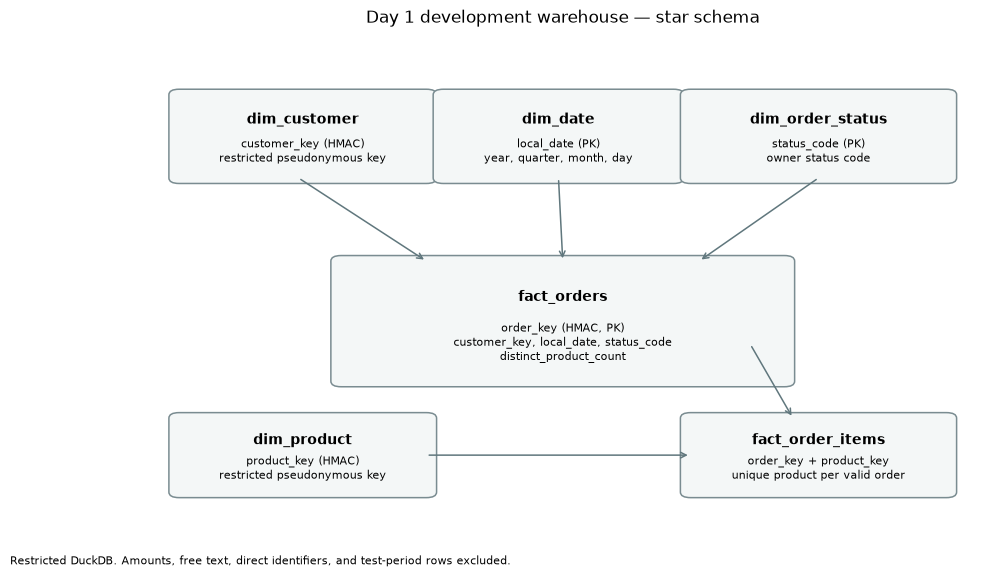

In [4]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(11, 6))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
boxes = {
    'dim_customer': (0.05, 0.70, 0.29, 0.18, 'customer_key (HMAC)\nrestricted pseudonymous key'),
    'dim_date': (0.36, 0.70, 0.27, 0.18, 'local_date (PK)\nyear, quarter, month, day'),
    'dim_order_status': (0.65, 0.70, 0.30, 0.18, 'status_code (PK)\nowner status code'),
    'fact_orders': (0.24, 0.26, 0.52, 0.26, 'order_key (HMAC, PK)\ncustomer_key, local_date, status_code\ndistinct_product_count'),
    'dim_product': (0.05, 0.02, 0.29, 0.16, 'product_key (HMAC)\nrestricted pseudonymous key'),
    'fact_order_items': (0.65, 0.02, 0.30, 0.16, 'order_key + product_key\nunique product per valid order'),
}
for title, (x, y, w, h, body) in boxes.items():
    patch = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.012', facecolor='#F4F7F7', edgecolor='#7A8C91', linewidth=1.1)
    ax.add_patch(patch)
    ax.text(x + w/2, y + h*0.70, title, ha='center', va='center', fontsize=10, fontweight='bold')
    ax.text(x + w/2, y + h*0.32, body, ha='center', va='center', fontsize=8)
for start, end in [((0.19,0.70),(0.34,0.52)), ((0.495,0.70),(0.50,0.52)), ((0.80,0.70),(0.66,0.52)), ((0.34,0.10),(0.65,0.10)), ((0.72,0.34),(0.77,0.18))]:
    ax.annotate('', xy=end, xytext=start, arrowprops={'arrowstyle':'->', 'color':'#60777D', 'linewidth':1.1})
ax.set_title('Day 1 development warehouse — star schema', pad=12)
fig.text(0.01, 0.005, 'Restricted DuckDB. Amounts, free text, direct identifiers, and test-period rows excluded.', fontsize=8)
fig.savefig(out_figures / 'day1_star_schema.png', dpi=160, bbox_inches='tight')
connection.close()

## Giới hạn diễn giải

Đây là EDA mô tả trên tập phát triển, không phải kết quả mô hình hay dự báo. Không có doanh thu/tiền vì định nghĩa tiền chưa được CP1 chốt. Không gán tháng nào là dịp lễ khi chưa có lịch lễ do chủ dự án cung cấp. Nhãn với W=180 có thể bỏ sót khách mua theo chu kỳ lễ khoảng một năm; kiểm tra W=365 chỉ thực hiện như độ nhạy trên phát triển.